In [1]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../datasets/heart.csv')

# StandardScaler
We’re scaling our data using `StandardScaler` to make sure all the features: 

- have mean = 0
- have std = 1

Why do we scale data to mean = 0 and standard deviation = 1? 

- Some algorithms (like SVM, KNN, Logistic Regression, PCA) work better when data is on the same scale.
- Features with bigger numbers could dominate smaller ones if we don’t scale.
- Centering at 0 makes calculations (like distances, gradients) more balanced. 


Formula:

$$
z = \frac{x - \bar{x}}{s}
$$

Where:  
- x = original value  
- bar{x} = mean of the feature/column  
- s = standard deviation of the feature/column
---

# Standard Deviation
Formula: 

$$
s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (x_i - \bar{x})^2}
$$

Lets do it with an example. We have a feature with 5 records: [40, 45, 50, 55, 60]

1. Calculate the mean:
$$
\bar{x} = \frac{40 + 45 + 50 + 55 + 60}{5} = \frac{250}{5} = 50
$$

2. Calculate the squared differences from the mean:
$$
(40 - 50)^2 = 100 \\
(45 - 50)^2 = 25 \\
(50 - 50)^2 = 0 \\
(55 - 50)^2 = 25 \\
(60 - 50)^2 = 100
$$

3. Sum the squared differences:
$$
\sum_{i=1}^5 (x_i - \bar{x})^2 = 100 + 25 + 0 + 25 + 100 = 250
$$

4. Divide by degrees of freedom (n-1 = 4):
$$
\frac{250}{4} = 62.5
$$

5. Take the square root to get the standard deviation:
$$
s = \sqrt{62.5} \approx 7.91
$$

### `The Standard deviation of this feature is approx 7.91`
---

# Z-Score

It tells you how many standard deviations a data point x is away from the mean. Dont forget that EACH value has its own Z-Score, its not a global thing. its in the range of the feature, independent from other features of the datapoint.

Positive z-score -- x is above the mean

Negative z-score -- x is below the mean

z-score = 0 -- x is exactly the mean


Formula: 

$$
z = \frac{x - \mu}{\sigma}
$$

- x: The data point you're looking at

- μ: The mean (average) of the dataset

- σ: The standard deviation of the dataset




6. Calculate the z-score for 40:
$$
z = \frac{40 - 50}{7.91} = \frac{-10}{7.91} \approx -1.26
$$

that means the value 40 is 1.26 standard deviation below the mean. given that the std is 7.91 we can easily prove that 7.91 * 1.26 = 9.96

---

In [3]:
np.random.seed(42)
data = {
    'Feature_A': np.random.normal(loc=50, scale=10, size=100),
    'Feature_B': np.random.uniform(low=0, high=100, size=100),
    'Feature_C': np.random.exponential(scale=20, size=100)
}
df = pd.DataFrame(data)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled_data, columns=df.columns)
# display(df, scaled_df)

so the values change, but the counts dont. and counts are what matter when viewing plots, but values are important for model traning.

## Values vs Counts
`Values (numbers):
`
- Change after scaling, shifted and stretched to have mean=0, std=1.

- Important for models that rely on math with distances, gradients, or assumptions about scale.

`Counts (how many points fall into each range/bin):`


- Don’t change after scaling — the shape of the distribution stays the same.

- When you look at histograms or density plots, the shape (counts per bin) stays intact.

- This means outliers, skewness, and patterns stay visible.

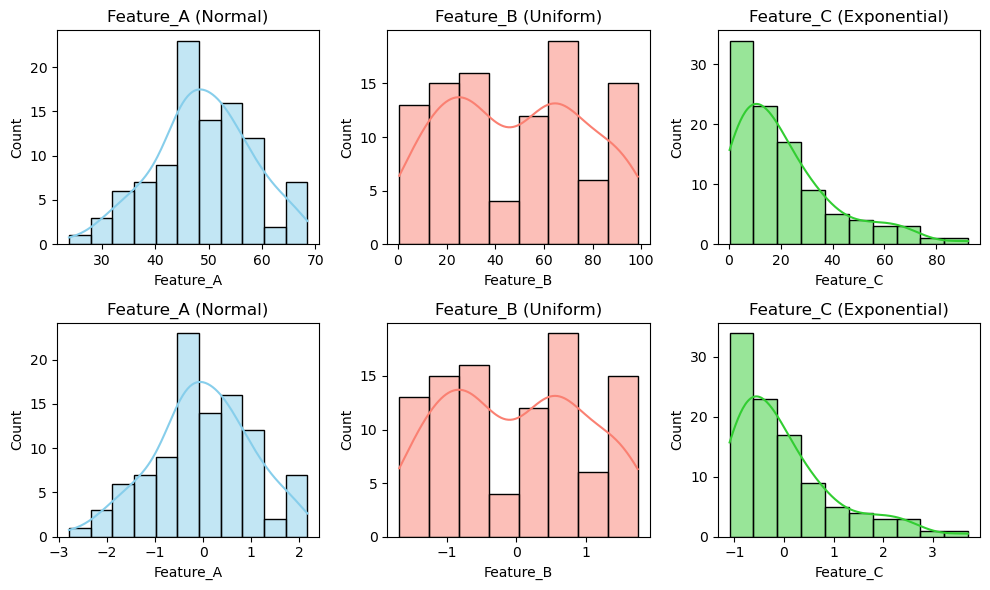

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

sns.histplot(df['Feature_A'], kde=True, ax=axes[0, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(df['Feature_B'], kde=True, ax=axes[0, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(df['Feature_C'], kde=True, ax=axes[0, 2], color='limegreen').set(title='Feature_C (Exponential)')

sns.histplot(scaled_df['Feature_A'], kde=True, ax=axes[1, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(scaled_df['Feature_B'], kde=True, ax=axes[1, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(scaled_df['Feature_C'], kde=True, ax=axes[1, 2], color='limegreen').set(title='Feature_C (Exponential)')

plt.tight_layout();

As you can see, the counts are the same on the Y axis, but the values on the x axis are much more similar and easy to train.

# Back to Standard Scaler

Text(0.5, 1.0, 'Scaled Data (First 5 Rows)')

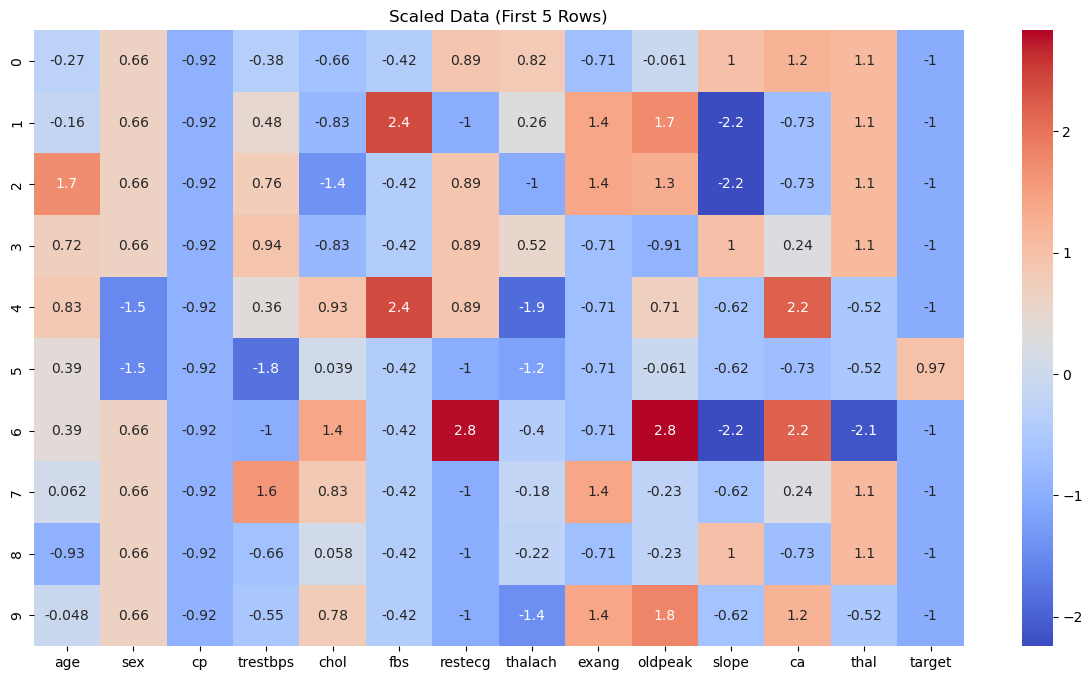

In [5]:
df = pd.read_csv('../datasets/heart.csv')
scaler = StandardScaler()
scaled = scaler.fit_transform(df)

fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(
    pd.DataFrame(scaled[:10], columns=df.columns),
    ax=ax,
    annot=True,
    cmap='coolwarm'
)
plt.title("Scaled Data (First 5 Rows)")

We have converted all of the values in each column to their standardized form (z-scores) so that each feature has a mean of 0 and a standard deviation of 1, because this makes sure no single feature dominates the others due to scale differences and helps many machine learning algorithms perform better.




You’re seeing standardized values (z-scores).

Example:

0 = this value is exactly at the mean.

+1 = this value is 1 standard deviation above the mean.

-1 = 1 standard deviation below the mean.

+2.2 = way higher than average.

-1.1 = slightly lower than average.

---

# MinMax Scaler

- It rescales your data to fit within a specific range — usually between 0 and 1.

- Keeps the shape of the distribution (no shifting to zero mean), but squishes values between the min and max limits.

- Great when you want all features in the same scale but don’t want to lose the original distribution shape.

$$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

Where:  
- \(x\) = original value  
- \(x_{\min}\) = minimum value of the feature  
- \(x_{\max}\) = maximum value of the feature  
- \(x'\) = scaled value between 0 and 1


Text(0.5, 1.0, 'Scaled Data (First 5 Rows)')

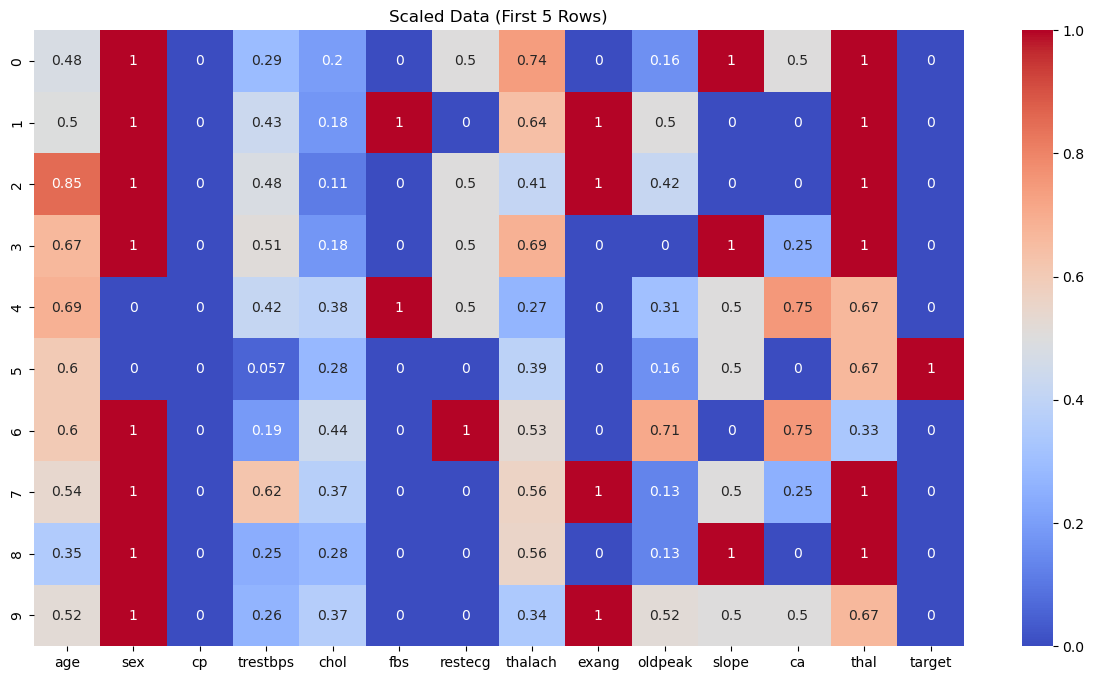

In [6]:
scaler = MinMaxScaler(feature_range=(0,1))
scaled = scaler.fit_transform(df)

fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(
    pd.DataFrame(scaled[:10], columns=df.columns),
    ax=ax,
    annot=True,
    cmap='coolwarm'
)
plt.title("Scaled Data (First 5 Rows)")

In [7]:
np.random.seed(42)
data = {
    'Feature_A': np.random.normal(loc=50, scale=10, size=100),
    'Feature_B': np.random.uniform(low=0, high=100, size=100),
    'Feature_C': np.random.exponential(scale=20, size=100)
}
df = pd.DataFrame(data)
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled_data, columns=df.columns)
# display(df, scaled_df)

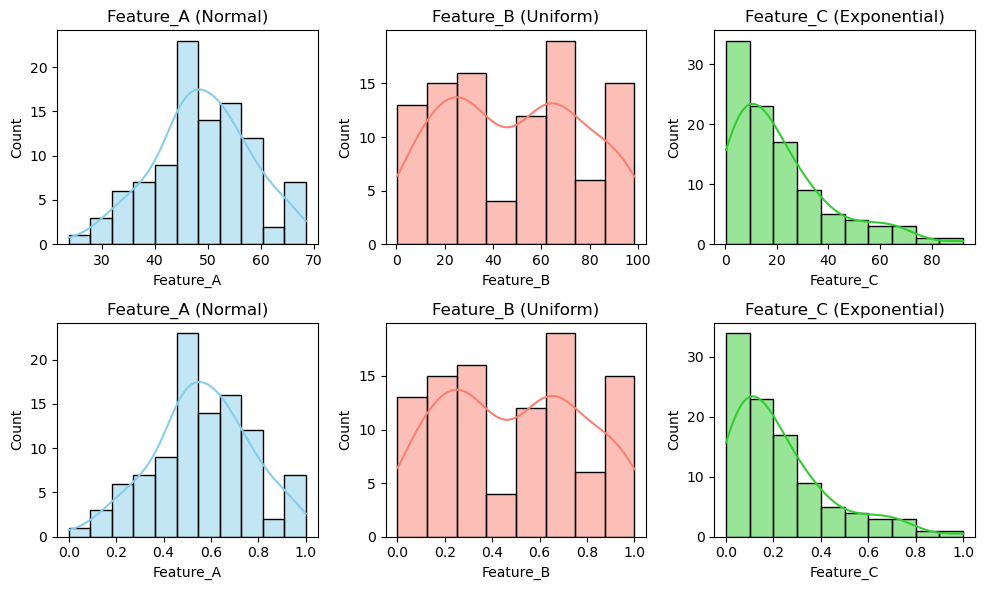

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

sns.histplot(df['Feature_A'], kde=True, ax=axes[0, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(df['Feature_B'], kde=True, ax=axes[0, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(df['Feature_C'], kde=True, ax=axes[0, 2], color='limegreen').set(title='Feature_C (Exponential)')

sns.histplot(scaled_df['Feature_A'], kde=True, ax=axes[1, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(scaled_df['Feature_B'], kde=True, ax=axes[1, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(scaled_df['Feature_C'], kde=True, ax=axes[1, 2], color='limegreen').set(title='Feature_C (Exponential)')

plt.tight_layout();

as you can see, the destribution is the same, but the values all range from 0 to 1. remember that we can change the range but the default is 0 to 1.

---

# Robust Scaler

$$
x' = \frac{x - \text{median}(x)}{\text{IQR}(x)}
$$

Where:  
- \(x\) = original value  
- \(\text{median}(x)\) = median of the feature  
- \(\text{IQR}(x) = Q_3 - Q_1\) (Interquartile Range)  
- \(x'\) = scaled value, centered around 0

- It scales data using statistics that are robust to outliers — mainly median and interquartile range (IQR).

- Unlike StandardScaler or MinMaxScaler, it won’t get wrecked if your data has extreme values (outliers).

- Good for datasets with outliers or heavy-tailed distributions.

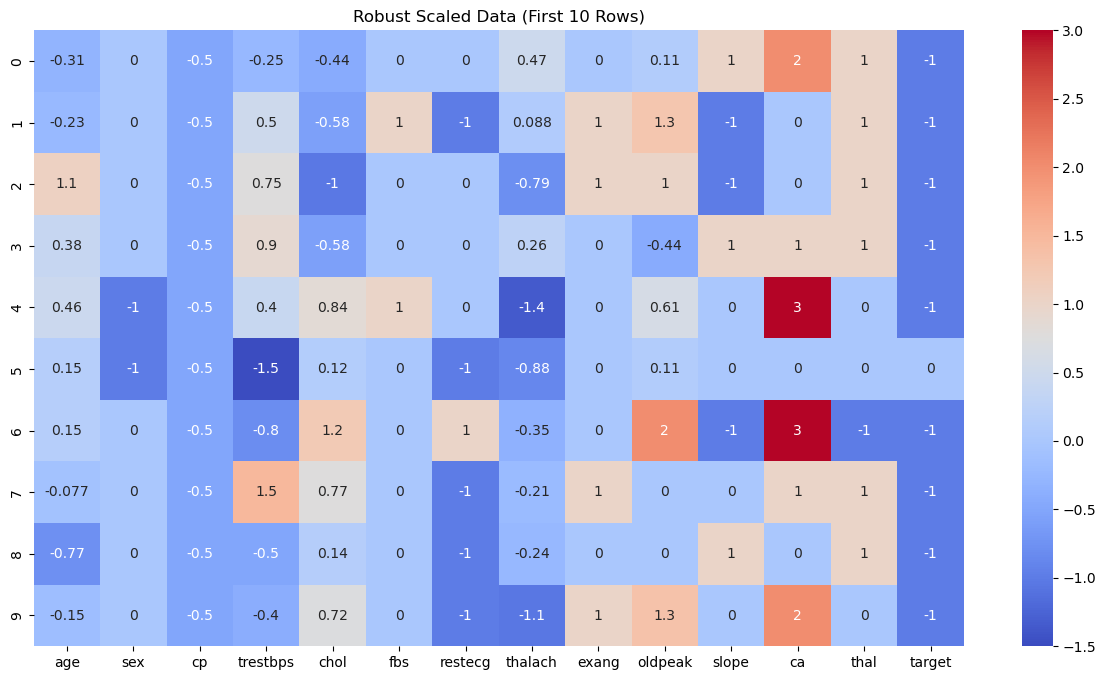

In [9]:
from sklearn.preprocessing import RobustScaler

df = pd.read_csv('../datasets/heart.csv')

scaler = RobustScaler()
scaled = scaler.fit_transform(df)

fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(
    pd.DataFrame(scaled[:10], columns=df.columns),
    ax=ax,
    annot=True,
    cmap='coolwarm'
)
plt.title("Robust Scaled Data (First 10 Rows)")
plt.show()


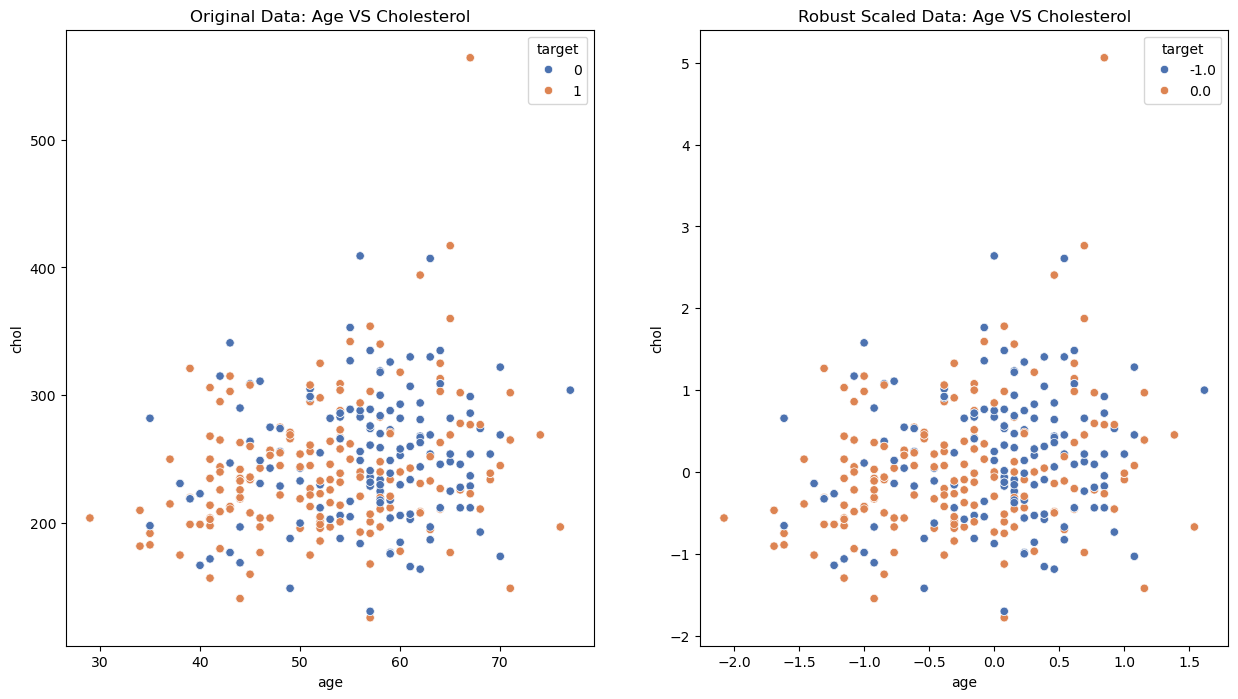

In [10]:
rob = RobustScaler()
Rscaled = rob.fit_transform(df)
Rscaled_df = pd.DataFrame(Rscaled, columns=df.columns)

fig, ax = plt.subplots(1, 2, figsize=(15,8))
sns.scatterplot(data=df, x='age', y='chol', hue='target', palette='deep', ax=ax[0])
ax[0].set(title="Original Data: Age VS Cholesterol")

sns.scatterplot(data=Rscaled_df, x='age', y='chol', hue='target', palette='deep', ax=ax[1])
ax[1].set(title="Robust Scaled Data: Age VS Cholesterol")

plt.show()

This code applies the RobustScaler to the dataset to reduce the impact of outliers by centering features around their median and scaling them based on the interquartile range. We then visualize the relationship between age and chol (cholesterol) before and after scaling, with data points colored by the target category. The side-by-side scatterplots clearly show how RobustScaler preserves the overall data structure while adjusting the scale, making features more comparable without being skewed by extreme values. This helps machine learning models handle outliers more effectively.

---

# Normalizer

- It scales each data point (row) individually to have unit norm (usually length 1).

- Unlike StandardScaler or MinMaxScaler that work column-wise (feature-wise), Normalizer works row-wise.

- Useful when you care about the direction of the data points but not their magnitude — common in text classification, clustering, or similarity tasks.



$$
\mathbf{x'} = \frac{\mathbf{x}}{\|\mathbf{x}\|_p} = \frac{\mathbf{x}}{\left(\sum_{i=1}^n |x_i|^p \right)^{\frac{1}{p}}}
$$

Where:  
- \(\mathbf{x} = (x_1, x_2, ..., x_n)\) is the original data point (row)  
- \(\|\mathbf{x}\|_p\) is the p-norm of the vector (default is Euclidean norm \(p=2\))  
- \(\mathbf{x'}\) is the normalized vector with length 1


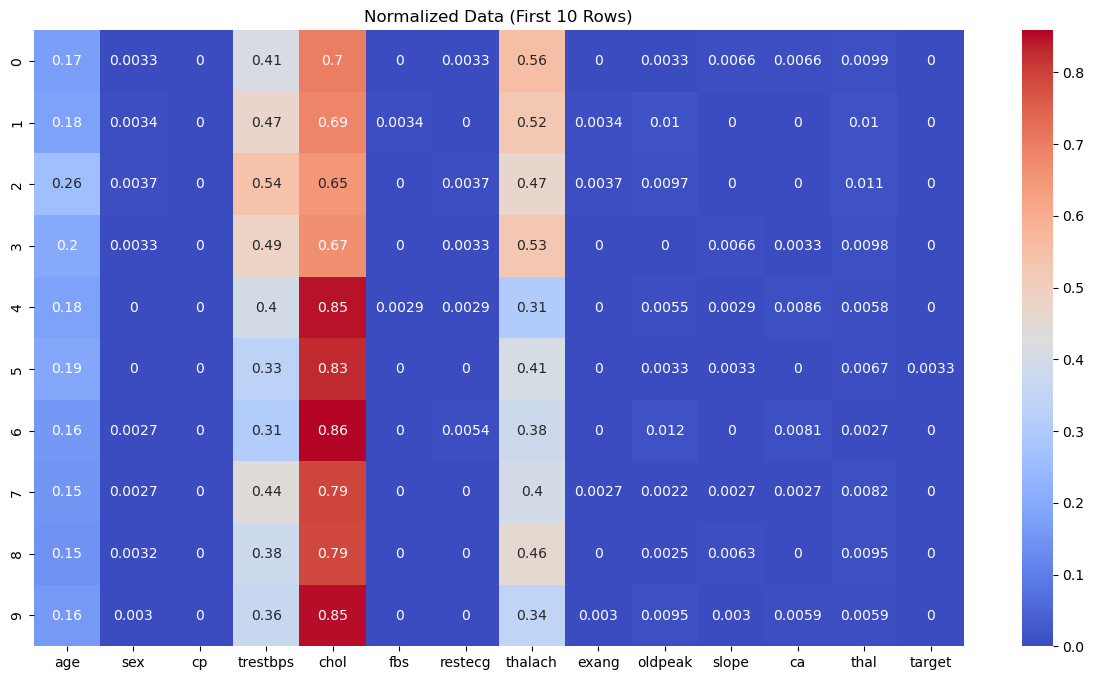

In [11]:
from sklearn.preprocessing import Normalizer

df = pd.read_csv('../datasets/heart.csv')

scaler = Normalizer()
scaled = scaler.fit_transform(df)

fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(
    pd.DataFrame(scaled[:10], columns=df.columns),
    ax=ax,
    annot=True,
    cmap='coolwarm'
)
plt.title("Normalized Data (First 10 Rows)")
plt.show()


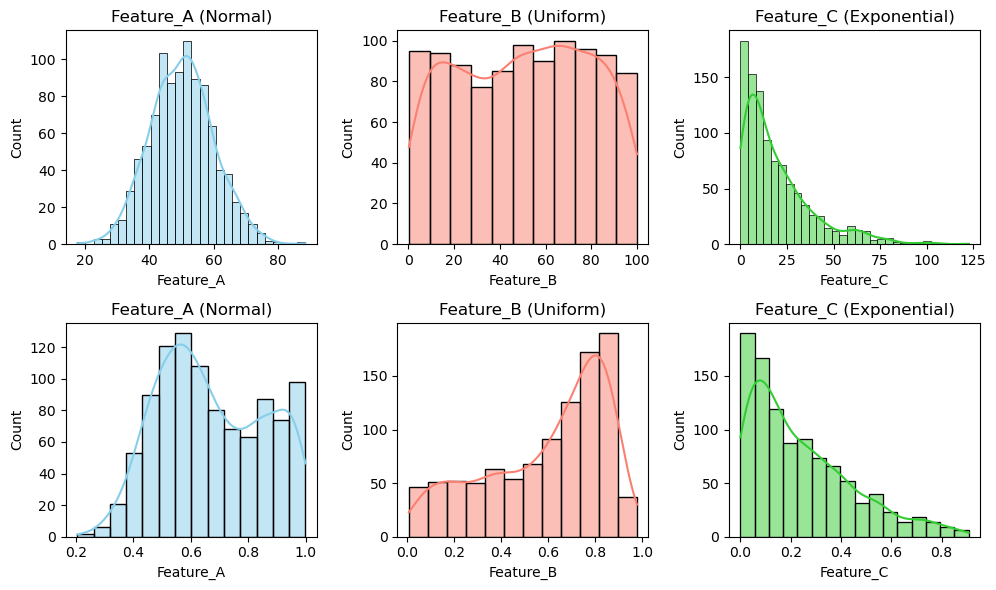

In [12]:
np.random.seed(42)
data = {
    'Feature_A': np.random.normal(loc=50, scale=10, size=1000),
    'Feature_B': np.random.uniform(low=0, high=100, size=1000),
    'Feature_C': np.random.exponential(scale=20, size=1000)
}
df = pd.DataFrame(data)
scaler = Normalizer()
scaled_data = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled_data, columns=df.columns)
# display(df, scaled_df)

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

sns.histplot(df['Feature_A'], kde=True, ax=axes[0, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(df['Feature_B'], kde=True, ax=axes[0, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(df['Feature_C'], kde=True, ax=axes[0, 2], color='limegreen').set(title='Feature_C (Exponential)')

sns.histplot(scaled_df['Feature_A'], kde=True, ax=axes[1, 0], color='skyblue').set(title='Feature_A (Normal)')
sns.histplot(scaled_df['Feature_B'], kde=True, ax=axes[1, 1], color='salmon').set(title='Feature_B (Uniform)')
sns.histplot(scaled_df['Feature_C'], kde=True, ax=axes[1, 2], color='limegreen').set(title='Feature_C (Exponential)')

plt.tight_layout();

Why does it look weird after normalization?
Because Normalizer scales rows, not columns — so each feature’s distribution changes as part of the whole vector being squished to length 1. It’s not about scaling features independently.

This is perfect for algorithms that care about vector directions (like cosine similarity), not raw values or distributions.

---

# PCA - Principal Component Analysis

PCA is a dimensionality reduction technique.

- It transforms the original features into a new set of uncorrelated features called Principal Components (PCs).

- The first PC captures the most variance, the second captures the next most (orthogonal to the first), and so on.

- Useful for simplifying datasets, visualizing high-dimensional data, and reducing noise.

In [13]:
# from sklearn.decomposition import PCA

# pca = PCA(n_components=2)
# reduced = pca.fit_transform(df)

# fig, ax = plt.subplots(figsize=(15,8))
# sns.heatmap(
#     pd.DataFrame(reduced[:10], columns=['PC1', 'PC2']),
#     ax=ax,
#     annot=True,
#     cmap='coolwarm'
# )
# plt.title("PCA Reduced Data (First 10 Rows)")
# plt.show()


In [14]:
# # Using 'chol' and 'age' features only for PCA
# features = data[['chol', 'age']]

# # Plot before PCA
# plt.figure(figsize=(12, 5))
# plt.subplot(1, 2, 1)
# sns.scatterplot(x='chol', y='age', hue='target', data=data, palette='Set2')
# plt.title('Before PCA (Cholesterol vs Age)')
# plt.xlabel('Cholesterol')
# plt.ylabel('Age')
# plt.legend()

# # Scale features
# scaler = StandardScaler()
# scaled_data = scaler.fit_transform(features)

# # PCA to 2 components
# pca = PCA(n_components=2)
# pca_data = pca.fit_transform(scaled_data)
# pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
# pca_df['target'] = data['target']

# # Plot after PCA
# plt.subplot(1, 2, 2)
# sns.scatterplot(x='PC1', y='PC2', hue='target', data=pca_df, palette='Set2')
# plt.title('After PCA (PC1 vs PC2)')
# plt.xlabel('PC1')
# plt.ylabel('PC2')
# plt.legend()

# plt.tight_layout()
# plt.show()


This code visualizes how the data looks before and after applying PCA (Principal Component Analysis).

Before PCA: It plots cholesterol (chol) against age (age), coloring points by the heart disease target label, so you see how different classes spread in these two features.

Scaling: It normalizes the features to have mean zero and unit variance, which is important so PCA treats all features fairly.

PCA: It reduces the two features into two new combined features (PC1 and PC2) that capture the main patterns in the data.

After PCA: It plots these new components, again colored by the target, letting you see if PCA reveals clearer group separation than the original features.

In [15]:
# from sklearn.feature_selection import SelectKBest , f_regression

# selector = SelectKBest(score_func=f_regression , k =4)
# K_best = selector.fit_transform(X_df,y)
# S_best = X_df.columns[selector.get_support()]
# list(S_best)

In [16]:
# from sklearn.linear_model import LassoCV

# lasso = LassoCV(cv=5)
# lasso.fit(X_df,y)
# ss = X_df.columns[lasso.coef_ < 0]
# ss